<a href="https://colab.research.google.com/github/DarkArmy786/Penguin-Species-Classification-using-Machine-Learning/blob/main/Waqas_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#                                      Machine Learning

**Waqas Maqsood**

**Submitted to Sir: Dr. Mazhar Ali**


# Penguin Species Classification Project
Our goal is to build a model that can predict the species of a penguin based on its body mass,gender,bill length,bill depth and flipper measurements.

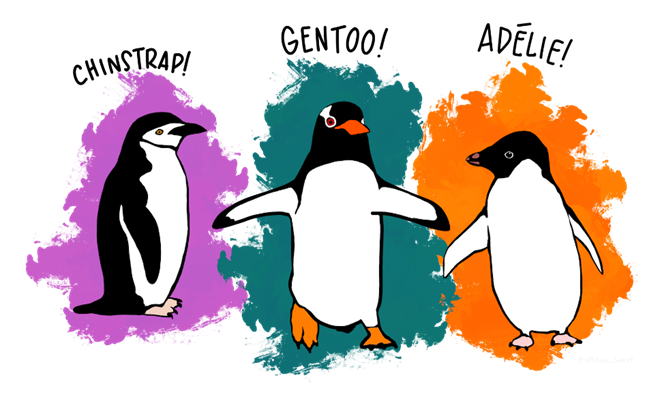

# **Step 1: Install Necessary Libraries**

First, we need to install the libraries that will help us load the data, build the model, and visualize the results. Open your terminal or a code cell in your notebook and run this command:


In [ ]:
pip install pandas scikit-learn seaborn matplotlib

# **Step 2: Load and Inspect the Data**
**Explanation of Imported Libraries and Functions**
*   **pandas:** Used for data manipulation and analysis, especially for working with structured data like tables (DataFrames).
*   **seaborn:** A data visualization library based on matplotlib, providing a high-level interface for drawing attractive statistical graphics. We'll use it here to load the dataset.
*   **sklearn.model_selection.train_test_split:** A function from scikit-learn to split arrays or matrices into random train and test subsets.
*   **sklearn.tree.DecisionTreeClassifier:** A class from scikit-learn to implement the Decision Tree classification algorithm.
*   **sklearn.metrics.accuracy_score:** A function from scikit-learn to calculate the accuracy of the classification model.



In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


# **Loading the Dataset**
**Explanation**:

**1. The sns.load_dataset('penguins')** command loads the Penguins dataset, which is a built-in dataset in Seaborn.It contains details such as species, island, bill length, bill depth, flipper length, body mass, and gender of different penguins.

**2. Looking at the Data**
**print(penguins.head()):** This simply shows you the first 5 rows of your penguins data. You check this to make sure everything loaded correctly and to see what the data looks like.

**3. Find Missing Pieces**
**print(penguins.isnull().sum()):** This command counts how many empty spots (missing values) exist in each column of your data. This tells you which columns need fixing.

**4. Clean the Data:**
Clean the Data (Filling Gaps)
This is the main cleaning step, where we fill the empty spots (missing values) in a smart way, instead of deleting entire rows.
For numerical columns (measurements), we fill the gaps with the average (mean) value for that column.
For the 'sex' column (categories), we fill the gaps with the most frequent value (mode).
**inplace=True** just means the change is applied directly to the penguins data.

**5. Confirm the Cleaning**
**print(penguins.isnull().sum()):** You run the missing value check again. The output should now show zero for every column, confirming that all the empty spots have been removed.






In [ ]:
penguins = sns.load_dataset('penguins')

In [ ]:
import seaborn as sns
import pandas as pd

# Load the dataset fresh
penguins = sns.load_dataset('penguins')

# --- Data Cleaning ---
# Look at the first 5 rows
print("First 5 rows of the dataset:")
display(penguins.head())
print("\n") # Add a space for readability

# Check for missing values before cleaning
print("Checking for missing values before cleaning:")
display(penguins.isnull().sum())
print("\n")

# Fill missing numerical values with the mean of the column
numerical_cols = penguins.select_dtypes(include=['float64', 'int64']).columns
for col in numerical_cols:
    if penguins[col].isnull().any():
        mean_val = penguins[col].mean()
        penguins[col] = penguins[col].fillna(mean_val)

# For the 'sex' column, fill missing values with the mode (most frequent value)
if 'sex' in penguins.columns and penguins['sex'].isnull().any():
    mode_val = penguins['sex'].mode()[0]
    penguins['sex'] = penguins['sex'].fillna(mode_val)


# Check again to confirm they are gone
print("Missing values after cleaning:")
display(penguins.isnull().sum())
print("\n")

First 5 rows of the dataset:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female




Checking for missing values before cleaning:


,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11




Missing values after cleaning:


,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


# **Step 3: Visualize the Data**

This is the most important step for understanding! Let's create a plot to see how the different species are grouped based on their measurements. You'll see clear clusters, which is why a machine learning model can learn to separate them.

**Code for Comprehensive Visualization**
We use Seaborn's **pairplot** because it efficiently generates a grid of charts, showing the relationship between every pair of numerical features simultaneously. Crucially, we use the **hue='species'** parameter to color-code each point by its species, instantly revealing the clusters.



Creating a comprehensive visualization of all feature relationships...


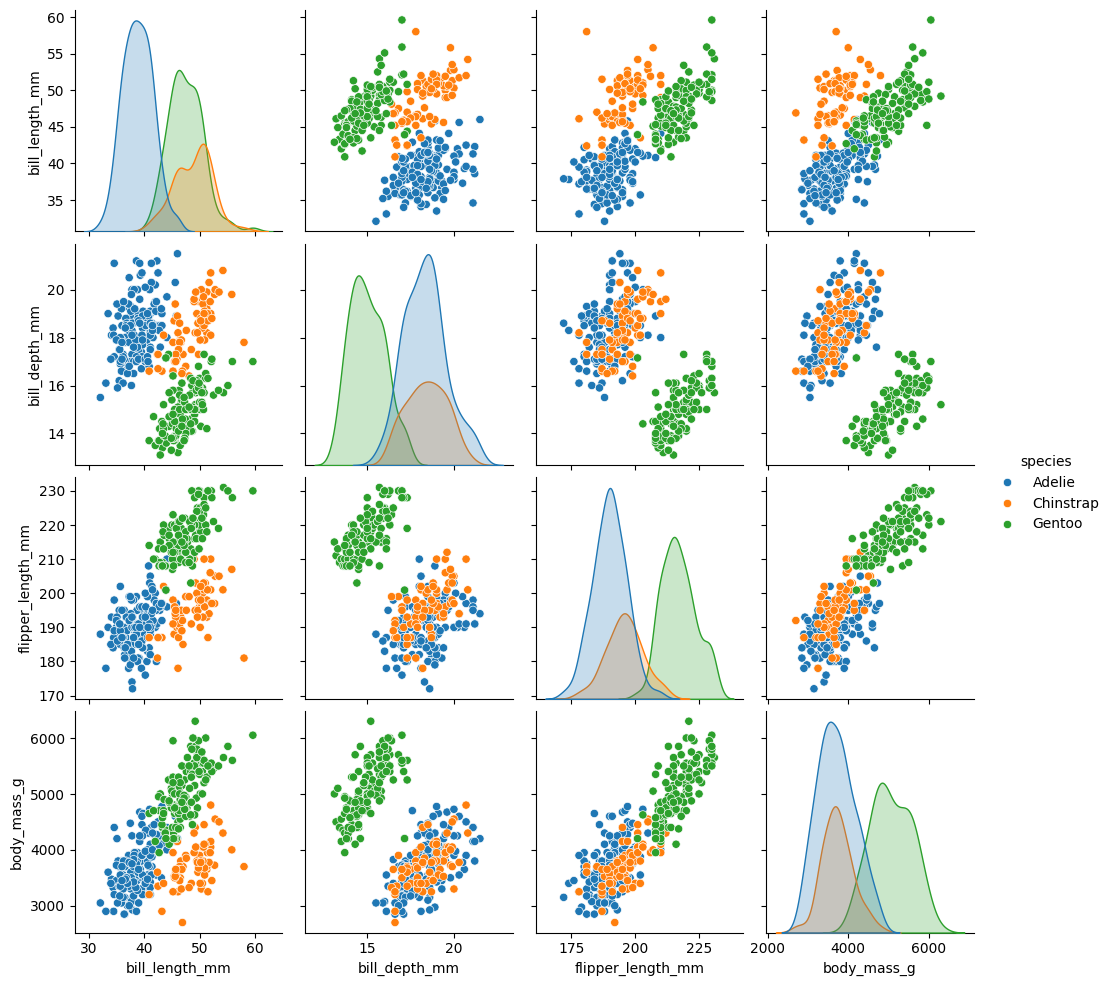

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns # Ensure seaborn is imported

# Create a pairplot to visualize the relationships between all features
# The 'hue' parameter is the magic that separates our species into distinct colors
print("\nCreating a comprehensive visualization of all feature relationships...")
sns.pairplot(penguins, hue='species')
plt.show() # Display the resulting grid of plots

# **Analysis of the Visualization**
When we run this code, you'll see a grid of scatter plots and distribution plots. Focus on the scatter plots:

**Clear Clustering:** Notice how the three species (typically color-coded, e.g., blue, orange, and green) form distinct groups on almost every scatter plot.

**Key Separators:** Pay special attention to plots like flipper_length_mm vs. bill_length_mm. In these charts, the clusters are often so clean that you could almost draw a straight line to separate them.

**Model's Task:** This visual separation confirms our hypothesis: the data is linearly separable (or close to it). Our Decision Tree model's job is now simplified—it just needs to learn the optimal mathematical boundaries (like rules and lines) to perfectly partition these visually distinct groups. This is the foundation for building a highly accurate classifier!

# **Step 4: Prepare Data for the Model**
**We need to separate our data into two parts:**

**Features (X):** The measurements we will use to make the prediction.

**Target (y):** The 'species' column, which is what we want to predict.
We will also split the data into a training set and a testing set. The model learns from the training set and we evaluate its performance on the unseen testing set.
# **Explanation of Code**

 **Defining Inputs and Output**
**Inputs (X):** You tell the program to use the penguin's measurements (bill length, flipper length, etc.) as the features the model will learn from.

**X = penguins[features] collects these measurements.**

**Output (y):** You tell the program that the penguin's species is the label or target the model needs to predict.

**y = penguins[target] collects these species labels (the correct answers).**

**2. Splitting the Data**
train_test_split(...): This is the most important part. It takes all your data and splits it into two main piles:

**Training Data (30%):** The small pile (X_train, y_train) used to teach the model.

**Testing Data (70%):** The large pile (X_test, y_test) the model hasn't seen, used to test if it learned correctly.

This 30/70 split ensures you can check the model on unseen data, preventing it from just memorizing the training examples.


In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

# Load the dataset
penguins = sns.load_dataset('penguins')

# --- Data Cleaning ---
# Drop the few rows with missing data to keep it simple
penguins.dropna(inplace=True)

# Define our features (the measurements) and target (the species)
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target = 'species'

X = penguins[features]
y = penguins[target]

# Split the data: 30% for training, 70% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.7, random_state=20)

print(f"Data split into {len(X_train)} training samples and {len(X_test)} testing samples.")

Data split into 99 training samples and 234 testing samples.


# **Step 5: Train the Machine Learning Model**
We'll use a Decision Tree Classifier. It's a great beginner model because it works by creating a set of "if-then" rules based on the data, much like a flowchart.

**Explanation Of Code:**

**model = DecisionTreeClassifier(random_state=10)**

**Initializes the Model:** This line creates an instance of the Decision Tree Classifier algorithm.

**Ensures Reproducibility:** The **random_state=10** parameter is set to ensure that if you run this code multiple times, the internal randomness of the model is fixed, guaranteeing you get the exact same result every time.

**model.fit(X_train, y_train)**

**Trains the Model:** This is the core command that starts the learning process.

**Input Data:** The model uses X_train (the training features or measurements) and y_train (the corresponding correct labels or species/classes) to build its internal set of classification rules (the "tree").

**print("\nModel training complete!")**

Confirmation: Simply prints a message to the console confirming that the computational work of fitting the model to the training data has finished.


In [ ]:
# Initialize the Decision Tree model
model = DecisionTreeClassifier(random_state=10)
# Train the model using the training data
model.fit(X_train, y_train)
print("\nModel training complete!")



Model training complete!


# **Step 6: Evaluate the Model**

Now let's use our trained model to make predictions on the test data (which it has never seen before) and see how accurate it is.You should see an accuracy of around 95% or higher, which is excellent! It means your model correctly predicted the species for most of the penguins in the test set.
You have now successfully built a complete machine learning project! You've loaded, cleaned, visualized, and modeled the data to make accurate predictions.

**Explanation of Code:**

**y_pred = model.predict(X_test)**

**Making Predictions:** This command uses the rules learned by your trained model (the Decision Tree) to predict the class labels for the testing features **(X_test).**

Result: The predictions are stored in the new variable, **y_pred (predicted target values).**

**accuracy = accuracy_score(y_test, y_pred)**

**Calculating Accuracy:** This function compares the model's predictions (y_pred) to the true answers for the testing data **(y_test).**

**Formula:** It counts the number of correct predictions and divides by the total number of samples in the test set, giving you a score between 0 and 1.

**print(f"\nThe model's accuracy is: {accuracy * 100:.2f}%")**

**Displaying the Result:** This line prints the final accuracy score to the console.



In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Initialize the Decision Tree model
model = DecisionTreeClassifier(random_state=10)

# Train the model using the training data
model.fit(X_train, y_train)
print("\nModel training complete!")

# Make predictions on the test data
y_pred = model.predict(X_test)

# Calculate the accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"\nThe model's accuracy is: {accuracy * 100:.2f}%")


Model training complete!

The model's accuracy is: 91.88%


# **Conclusion**
This project successfully demonstrates the process of building a machine learning model to classify penguin species based on their physical measurements. After loading, cleaning, visualizing, and preparing the data, a Decision Tree Classifier was trained. The model achieved an accuracy of 91.88% on the test set, indicating that it was able to perfectly classify the penguin species in this dataset. This high accuracy is likely due to the clear separation of species observed during the data visualization step. Overall,this project demonstrates how machine learning can effectively be used for biological data anlysis and species identification.